# Data exploration using subplots with MATPLOTLIB 

The purpose of this tutorial is to help you get to grips with solving basic indexing and data exploration problems. Typically, there is a library to do this sort of thing (e.g. see the seaborne example at the end), but it is sometimes useful to get an idea for what is going on 'under the hood'.

Have a look at the reference for matplotlib, here: https://matplotlib.org/


## Loading and plotting datasets

<span style="color:rgb(170,0,0)">**Task:**</span>  Try to plot these functions in the cell below, in similarly to above Go through the cells below, execute the code and try to understand it

In [1]:
#PRESS <Ctrl>+<Enter> to execute this cell

#In this cell, we load the iris/flower dataset we talked about in class
from sklearn import datasets
import matplotlib.pyplot as plt

iris = datasets.load_iris()

# view a description of the dataset
print(iris.DESCR)


.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [2]:
#directive to plot inline
%matplotlib inline


### Simple scatter-plot in 2D 

Text(0, 0.5, 'Sepal width')

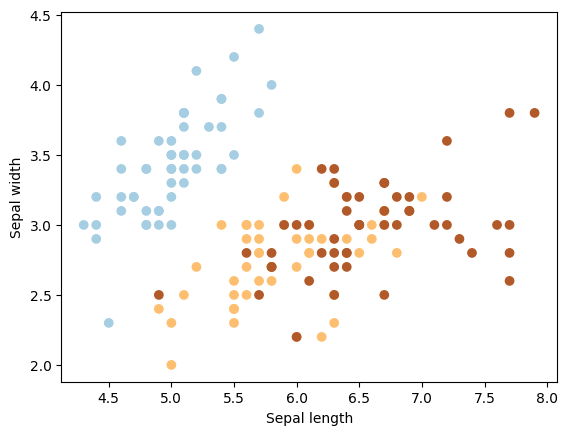

In [3]:
#PRESS <Ctrl>+<Enter> to execute this cell

#This populates info regarding the dataset.  Amongst others, we can see that the 'features' used are sepal length and width and petal length and width
#Lets plot sepal length against sepal width, using the target labels (which flower)
X=iris.data
Y=iris.target

#first two features are sepal length and sepal width
plt.scatter(X[:, 0], X[:, 1], c=Y, cmap=plt.cm.Paired)
plt.xlabel('Sepal length')
plt.ylabel('Sepal width')


### Parameterising the above to plot different feature combinations

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


Text(0, 0.5, 'petal width (cm)')

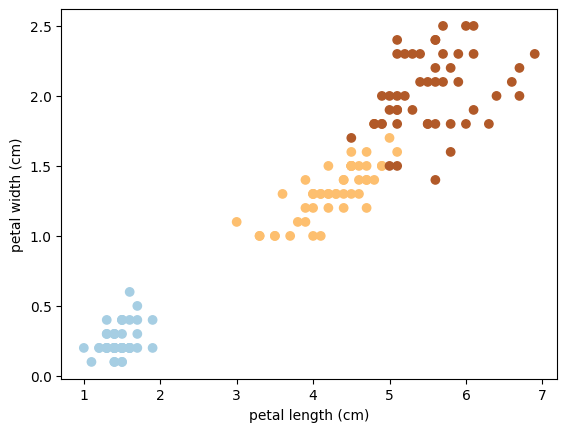

In [4]:

feature_names = iris.feature_names
print(feature_names)

# we can index the features using variables, e.g.
i = 2
j = 3
# (remember that indices in python start at 0)

#first two features are sepal length and sepal width
plt.scatter(X[:, i], X[:, j], c=Y, cmap=plt.cm.Paired)
plt.xlabel(feature_names[i])
plt.ylabel(feature_names[j])

#! Try this for different values of i and j


###  Histograms

Text(0, 0.5, 'instances')

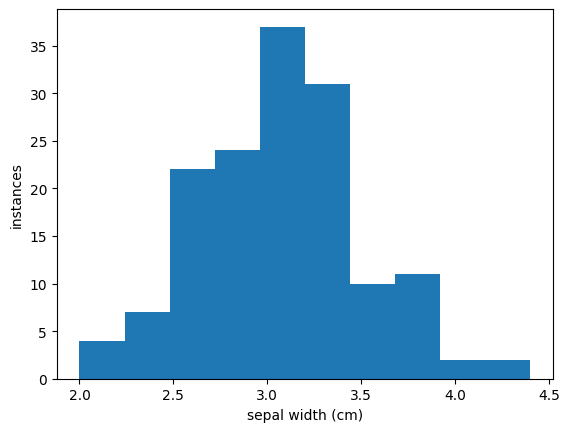

In [5]:
#here is a simple histogram plot
i = 1
plt.hist(X[:,i])
plt.xlabel( feature_names[i] )
plt.ylabel( 'instances' )


###  Plotting Subfigures
* ``add_subplot(wyz)`` means create a figure with w x z subplots (w rows, z columns).  Now switch to the subfigure z and write the plot.

Text(0, 0.5, 'sepal width (cm)')

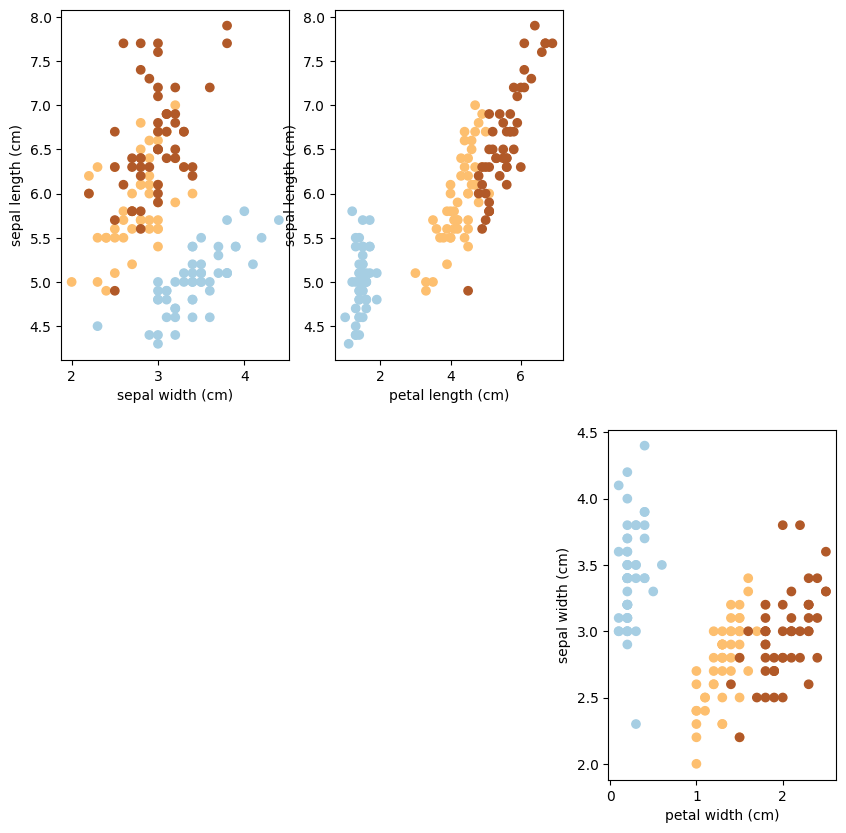

In [6]:
#here's how to create a figure with multiple subplots
fig = plt.figure(figsize=(10,10))  # 10x10 inch figure
n = len(feature_names)

#this creates a 2x3 grid (6 figures), and first we are plotting subfigure 1 (this is what 231 means -- it can also be 2,3,1)
ax = fig.add_subplot(231) 
i = 1
j = 0

# This time we are drawing scatter on the subplot axes (ax) directly. 
ax.scatter(X[:, i], X[:, j], c=Y, cmap=plt.cm.Paired)
# Note: the set_xlabel/y_label functions have different names from when they are called using the plt object 
ax.set_xlabel(feature_names[i])
ax.set_ylabel(feature_names[j])

# now add a 2nd subplot
ax = fig.add_subplot(232) 
i = 2
j = 0

# This time we are drawing scatter on the subplot axes (ax) directly. 
ax.scatter(X[:, i], X[:, j], c=Y, cmap=plt.cm.Paired)
# Note: the set_xlabel/y_label functions have different names from when they are called using the plt object 
ax.set_xlabel(feature_names[i])
ax.set_ylabel(feature_names[j])

# ...
# now skip to the 6th subplot
ax = fig.add_subplot(236) 
i = 3
j = 1

# This time we are drawing scatter on the subplot axes (ax) directly. 
ax.scatter(X[:, i], X[:, j], c=Y, cmap=plt.cm.Paired)
# Note: the set_xlabel/y_label functions have different names from when they are called using the plt object 
ax.set_xlabel(feature_names[i])
ax.set_ylabel(feature_names[j])



### Using loops to make this a bit nicer...

* Idea: use 2 nested ```for``` loops to plot a scatter plot for every feature combination, e.g.

```for iRrows = range(0,4) 
       for iColumns = range(0,4) ```
  where iRows and iColumns index the features.
 
 
 
* Substitute a scatter plot with a histogram on the diagonal, i.e. when ```iRows==iColumns```

### When in doubt, have a look at seaborne
 This is what you might typically use when working with data. 


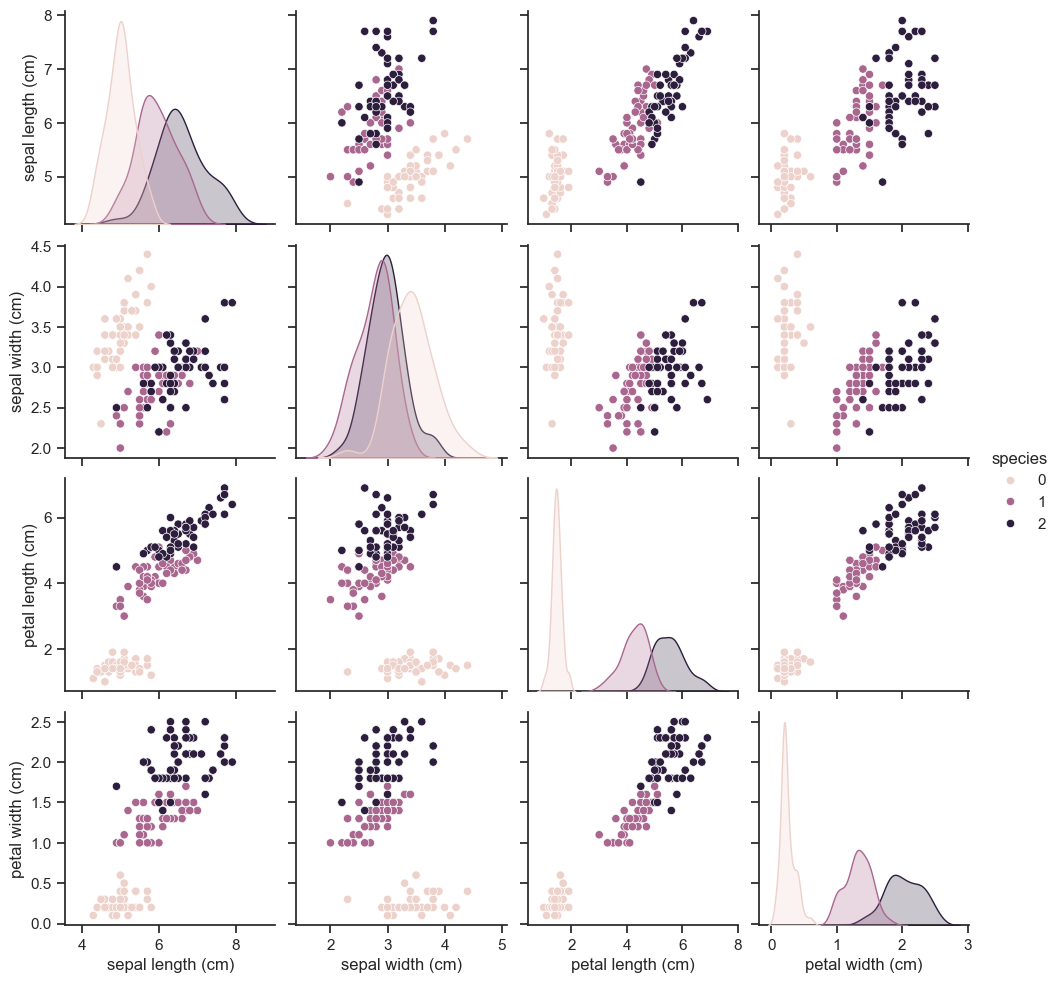

In [8]:
import seaborn as sns
import pandas as pd
sns.set(style="ticks")

df = pd.DataFrame(iris.data, columns = iris.feature_names )
df['species'] = iris.target

sns.pairplot(df, hue="species")
